# Climate finance and forest-restoration potential

## Purpose and scope

This deep dive compares two separate exercises. The first applies the specified 2% rate to annual GCW to describe a hypothetical allocation by study unit and economic group. The second uses the Busch et al. forest-restoration framework and data to examine potential 30-year CO₂ supply, cell costs and country coverage.

The 2% allocation is not observed finance or an estimated funding need. Restoration supply is a modelled opportunity and does not directly price protection of existing forests. The two exercises have different units and are not combined into one monetary total.

## Load the allocation and restoration outputs

The 2% scenario table reports the hypothetical annual GCW allocation. Restoration tables report the availability of Busch country curves and the reconstructed action-cost results. The common input table keeps allocation, restoration quantities and discounting assumptions in separate fields.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = RESULTS / 'validation'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: C:\Users\aurel\Desktop\M2\Stage ecoseas-csm\CSM\BNC2 paper\repo


## 2. Examine how the 2% GCW scenario is distributed

The allocation is proportional to the annual GCW value of each eligible study unit, then summarized by economic group. Compare both the total assigned to a group and its share of the global scenario; the median per-unit value describes a different aspect of the distribution.

In [2]:
allocation = pd.read_csv(TABLES / 'Table4_our_2pct_gcw_allocation.csv')
assumptions = pd.read_csv(TABLES / 'Supplementary_deforestation_scenarios.csv')
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')

# Reconstruct the stipulated allocation from annual GCW and compare group sums with Table 4.
allocation_rate = 0.02
gcw = pd.to_numeric(accounts['gcw_usd2015_yr_mean'], errors='coerce')
exclude = accounts['exclude_from_country_sum'].fillna(False).astype(bool)
eligible = gcw.notna() & ~exclude
accounts.loc[eligible, 'reconstructed_allocation_usd2015_yr'] = allocation_rate * gcw.loc[eligible]
reconstructed = accounts.loc[eligible].groupby('groups', dropna=False)['reconstructed_allocation_usd2015_yr'].sum().div(1e9).rename('reconstructed_billion_usd2015').reset_index()
comparison = allocation.merge(reconstructed, left_on='group', right_on='groups', how='outer')
comparison['difference_billion_usd2015'] = comparison['reconstructed_billion_usd2015'] - comparison['annual_allocation_billion_usd2015']
display(comparison)
display(assumptions.loc[assumptions['metric'].astype(str).str.contains('rate|allocation|discount', case=False, na=False)])


C:\Users\aurel\AppData\Local\Temp\ipykernel_28892\1590006676.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  accounts.loc[eligible, 'reconstructed_allocation_usd2015_yr'] = allocation_rate * gcw.loc[eligible]


,group,units,annual_allocation_billion_usd2015,share_of_total_pct,median_allocation_per_unit_million_usd2015,groups,reconstructed_billion_usd2015,difference_billion_usd2015
0,Developed economies,62,72.239007,43.720574,113.724556,Developed economies,72.239007,8.795382e-10
1,Developing economies,80,68.601312,41.518964,156.314013,Developing economies,68.601312,-7.365813e-09
2,LDCs,37,21.089087,12.763561,185.188891,LDCs,21.089087,-3.881979e-10
3,SIDS,57,3.299455,1.996900,1.259196,SIDS,3.299455,-3.763221e-10
4,Total,236,165.228860,100.000000,NaN,NaN,NaN,NaN
5,Unclassified,0,0.000000,0.000000,NaN,NaN,NaN,NaN


,metric,value,unit,assumption_or_formula,discount_rate,our_allocation_rate
4,Perpetuity value of annual lost GCW at 2% disc...,0.933854,trillion US$2015,Annual lost GCW value / 0.02; perpetual consta...,0.02,NaN


### Visual summary: annual allocation by economic group

The bars show the hypothetical annual amount assigned under the same 2% rule. They do not show payments made, pledged finance or a recommended contribution.

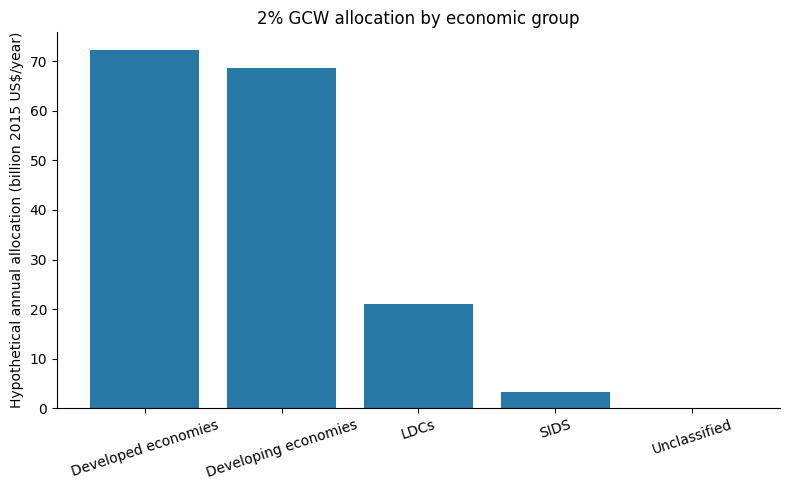

In [3]:
allocation_plot = allocation.loc[allocation["group"].ne("Total")].copy()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(allocation_plot["group"], allocation_plot["annual_allocation_billion_usd2015"], color="#2878A5")
ax.set_ylabel("Hypothetical annual allocation (billion 2015 US$/year)")
ax.set_title("2% GCW allocation by economic group")
ax.tick_params(axis="x", rotation=18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Examine restoration quantity, costs and coverage

The restoration outputs use the cell-level inputs and equations from Busch et al. to reconstruct forest-restoration supply and costs. The country summary shows which source curves are available and how much capacity could be covered by the available reconstruction. Coverage is part of the result: a missing country curve is not a zero-cost restoration opportunity.

In [4]:
coverage = pd.read_csv(TABLES / 'Supplementary_Busch_action_cost_coverage.csv')
busch = pd.read_csv(TABLES / 'Supplementary_Busch_action_cost_by_unit.csv')
display(coverage)
display(busch.head(20))
print('Busch output columns:', busch.columns.tolist())

,status,units,reported_loss_capacity_tco2_yr,target_discounted_30yr_tco2,share_of_all_reported_loss_pct,category
0,no_country_curve_in_published_table,42,1.698942e+07,2.611690e+08,50.900964,No country curve in published table
1,target_exceeds_published_supply_at_100,12,3.489236e+06,5.363811e+07,10.453887,Target exceeds published supply at $100/tCO2
2,target_within_positive_price_curve,13,1.663293e+06,2.556889e+07,4.983290,Target within positive-price range
3,target_within_supply_at_nonpositive_price,17,7.471194e+06,1.148506e+08,22.383990,Above -$20 and at or below $0/tCO2
4,target_within_supply_at_or_below_minus20,16,3.764259e+06,5.786589e+07,11.277868,At or below -$20/tCO2


,UNIT_CODE,ISO3,name,region,iso3,groups,reported_loss_capacity_tco2_yr,target_discounted_30yr_tco2,busch_curve_available,source_quantity_at_minus20_tco2_pv,source_quantity_at_zero_tco2_pv,source_quantity_at_100_tco2_pv,marginal_price_lower_usd2020_tco2,marginal_price_upper_usd2020_tco2,status,annualized_uniform_price_payment_lower_usd2020_yr_partial,annualized_uniform_price_payment_upper_usd2020_yr_partial,annualized_uniform_price_payment_lower_usd2015_yr_partial,annualized_uniform_price_payment_upper_usd2015_yr_partial
0,BRA,BRA,Brazil,Americas,BRA,Developing economies,1.126536e+07,1.731761e+08,False,NaN,NaN,NaN,NaN,NaN,no_country_curve_in_published_table,NaN,NaN,NaN,NaN
1,CHN,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Asia,CHN,Developing economies,1.315226e+06,2.021824e+07,True,1680573.0,112000000.0,4.780000e+09,NaN,0.0,target_within_supply_at_nonpositive_price,NaN,NaN,NaN,NaN
2,CAN,CAN,Canada,Americas,CAN,Developed economies,1.491670e+05,2.293062e+06,False,NaN,NaN,NaN,NaN,NaN,no_country_curve_in_published_table,NaN,NaN,NaN,NaN
3,AUS,AUS,Australia,Oceania,AUS,Developed economies,2.175637e+06,3.344488e+07,False,NaN,NaN,NaN,NaN,NaN,no_country_curve_in_published_table,NaN,NaN,NaN,NaN
4,COD,COD,Democratic Republic of the Congo,Africa,COD,LDCs,9.713073e+05,1.493137e+07,True,46000000.0,194000000.0,8.380000e+08,-20.0,-20.0,target_within_supply_at_or_below_minus20,NaN,NaN,NaN,NaN
5,IDN,IDN,Indonesia,Asia,IDN,Developing economies,3.725915e+05,5.727644e+06,True,11000000.0,65000000.0,1.100000e+09,-20.0,-20.0,target_within_supply_at_or_below_minus20,NaN,NaN,NaN,NaN
6,IND,IND,India,Asia,IND,Developing economies,2.218650e+06,3.410609e+07,True,8716857.0,109000000.0,1.500000e+09,NaN,0.0,target_within_supply_at_nonpositive_price,NaN,NaN,NaN,NaN
7,MEX,MEX,Mexico,Americas,MEX,Developing economies,6.816678e+05,1.047890e+07,True,73000000.0,701000000.0,1.910000e+09,-20.0,-20.0,target_within_supply_at_or_below_minus20,NaN,NaN,NaN,NaN
8,AGO,AGO,Angola,Africa,AGO,LDCs,1.748833e+06,2.688385e+07,True,868254.6,5831668.0,1.790000e+07,NaN,NaN,target_exceeds_published_supply_at_100,NaN,NaN,NaN,NaN
9,COL,COL,Colombia,Americas,COL,Developing economies,4.571140e+05,7.026963e+06,True,81200000.0,223000000.0,1.240000e+09,-20.0,-20.0,target_within_supply_at_or_below_minus20,NaN,NaN,NaN,NaN


Busch output columns: ['UNIT_CODE', 'ISO3', 'name', 'region', 'iso3', 'groups', 'reported_loss_capacity_tco2_yr', 'target_discounted_30yr_tco2', 'busch_curve_available', 'source_quantity_at_minus20_tco2_pv', 'source_quantity_at_zero_tco2_pv', 'source_quantity_at_100_tco2_pv', 'marginal_price_lower_usd2020_tco2', 'marginal_price_upper_usd2020_tco2', 'status', 'annualized_uniform_price_payment_lower_usd2020_yr_partial', 'annualized_uniform_price_payment_upper_usd2020_yr_partial', 'annualized_uniform_price_payment_lower_usd2015_yr_partial', 'annualized_uniform_price_payment_upper_usd2015_yr_partial']


## 4. Compare the natural-regeneration soil scenarios

The reference scenario uses Busch et al.'s natural-regeneration soil rate (0.415107735 tC/ha/year). Two alternatives set that rate to zero or to 0.338 tC/ha/year, the converted mean reported by Post and Kwon (2000). The plantation soil rate stays fixed. For each alternative, the cell method choice and the country supply/cost results are recalculated; these are deterministic sensitivity scenarios, not confidence intervals.


In [5]:
BUSCH_LABEL = "mangrove_refresh_20261023"
sensitivity_dir = VALIDATION / "busch_reconstruction"
sensitivity_path = sensitivity_dir / f"busch_{BUSCH_LABEL}_soil_sensitivity_country.csv"
sensitivity_curves_path = sensitivity_dir / f"busch_{BUSCH_LABEL}_soil_sensitivity_price_curves.csv"

if sensitivity_path.is_file() and sensitivity_curves_path.is_file():
    soil_sensitivity = pd.read_csv(sensitivity_path)
    sensitivity_summary = (
        soil_sensitivity.groupby("soil_scenario", dropna=False)
        .agg(
            nr_soil_rate_tC_ha_yr=("nr_soil_rate_tC_ha_yr", "first"),
            entities=("iso3", "nunique"),
            nr_cells=("natural_regeneration_cells_selected", "sum"),
            plantation_cells=("plantation_cells_selected", "sum"),
            method_switches=("method_switches_vs_busch_reference", "sum"),
            available_supply_at_max_price_tco2=("available_discounted_tco2_at_max_price", "sum"),
        )
        .reset_index()
    )
    display(sensitivity_summary)
    sensitivity_curves = pd.read_csv(sensitivity_curves_path)
    global_sensitivity_curves = (
        sensitivity_curves.groupby(["soil_scenario", "price_usd2015_per_tco2"], as_index=False)
        ["cumulative_supply_discounted_tco2"].sum()
    )
    fig, ax = plt.subplots(figsize=(8, 5))
    for scenario, rows in global_sensitivity_curves.groupby("soil_scenario"):
        ax.plot(rows["price_usd2015_per_tco2"], rows["cumulative_supply_discounted_tco2"] / 1e6, label=scenario)
    ax.set_xlabel("Carbon price (2015 US$/tCO₂)")
    ax.set_ylabel("Cumulative modelled supply (MtCO₂, discounted over 30 years)")
    ax.set_title("Global restoration supply under alternative natural-regeneration soil rates")
    ax.legend(title="Soil scenario")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
else:
    print(
        "Soil-rate sensitivity outputs are not present. They are generated with the cell-level Busch reconstruction; "
        "the main run skipped that download because the 12.4 GB input archive was unavailable locally."
    )


Soil-rate sensitivity outputs are not present. They are generated with the cell-level Busch reconstruction; the main run skipped that download because the 12.4 GB input archive was unavailable locally.


## 5. Keep allocation and restoration costs on their own scales

The allocation is an annual hypothetical amount in 2015 US dollars. Busch restoration prices originate in 2020 US dollars per tonne of CO₂ and are converted for the account comparison; reconstructed supply is discounted over 30 years. Compare the exercises as distinct quantities, and use the displayed cost and coverage fields rather than treating the 2% allocation as an observed budget.

In [6]:
comparison_path = VALIDATION / 'finance_action_cost_comparison.json'
if comparison_path.exists():
    import json
    comparison = json.loads(comparison_path.read_text(encoding='utf-8'))
    display(pd.Series(comparison, name='value').to_frame())
else:
    print('The validation JSON is not present; the table exports above remain available.')

,value
gibbs_gmw_gcw_usd2015_yr,8261443009142.151367
our_allocation_rate,0.02
our_2pct_gcw_allocation_usd2015_yr,165228860182.843018
global_100bn_30yr_pledge_usd_cumulative,3000000000000.0
annual_allocation_pledge_unit_mismatch,annual GCW minus 30-year cumulative allocation...
busch_article,"Busch et al. (2024), 30-year marginal abatemen..."
busch_cost_curve,least-cost of natural regeneration vs plantati...
discount_factor_years_1_to_30,15.372451
positive_loss_reporters,100
positive_loss_total_tco2_yr,33377399.801651
